<a href="https://colab.research.google.com/github/gabrielbf15-nuvem/Projeto_2026/blob/main/U3_A4_VISUALIZACAO_DE_DADOS_EM_PYTHON.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PRIMEIRAS LINHAS:
   id_venda data_venda    produto    categoria  valor_venda
0         1 2023-01-01  Produto A  Eletrônicos       1500.0
1         2 2023-01-05  Produto B       Roupas        350.0
2         3 2023-02-10  Produto C  Eletrônicos       1200.0
3         4 2023-03-15  Produto D       Livros        200.0
4         5 2023-03-20  Produto E  Eletrônicos        800.0

RESUMO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id_venda     14 non-null     int64         
 1   data_venda   14 non-null     datetime64[ns]
 2   produto      14 non-null     object        
 3   categoria    14 non-null     object        
 4   valor_venda  14 non-null     float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 692.0+ bytes

ESTATÍSTICAS:
count      14.000000
mean      628.571429
std       407.484915
min 

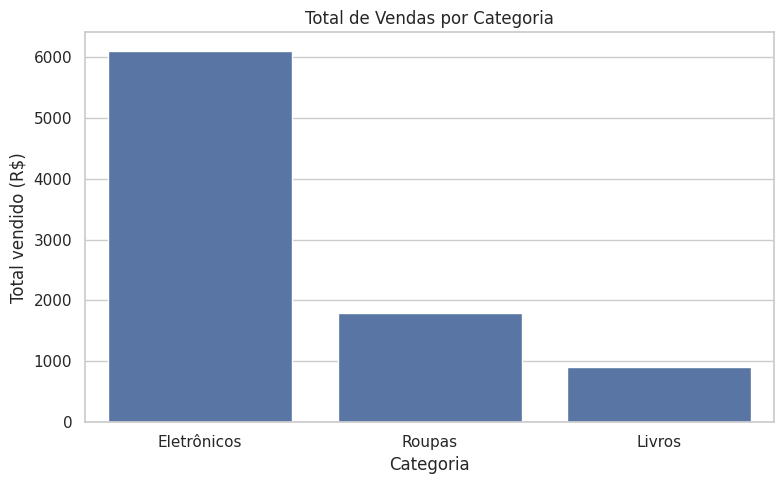

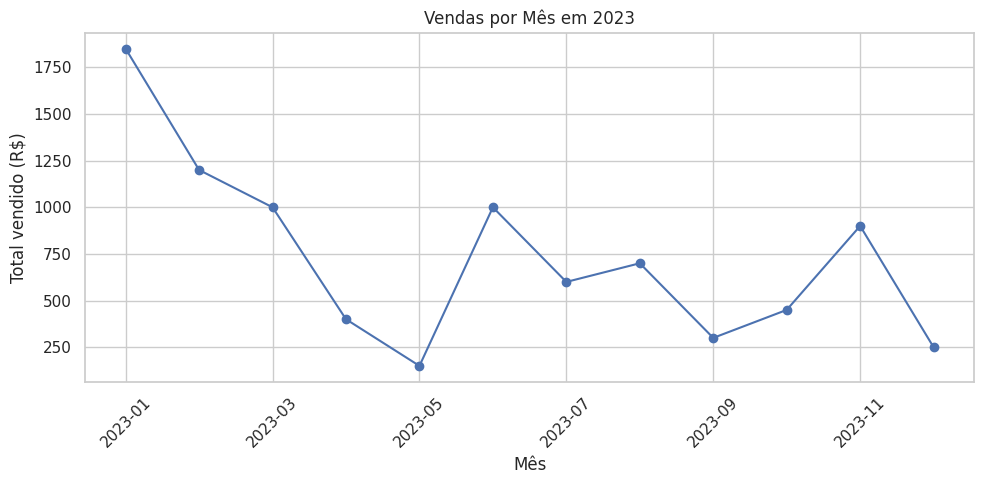


CONCLUSÃO AUTOMÁTICA:
Total vendido: R$ 8,800.00
Categoria com maior faturamento: Eletrônicos
Mês com maior faturamento: 2023-01


In [1]:
# TRABALHO: VISUALIZAÇÃO DE DADOS EM PYTHON

# Unidade 3 - Introdução à Análise de Dados com Python

# Aula 4 - Visualização de Dados em Python



import sqlite3

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns



# 1. Conectar ao banco SQLite e criar a tabela.

conexao = sqlite3.connect("dados_vendas.db")

cursor = conexao.cursor()

cursor.execute("DROP TABLE IF EXISTS vendas1")

cursor.execute("""

CREATE TABLE vendas1 (

    id_venda INTEGER PRIMARY KEY AUTOINCREMENT,

    data_venda DATE,

    produto TEXT,

    categoria TEXT,

    valor_venda REAL

)

""")



# 2. Inserir os 14 registros de exemplo do roteiro.

vendas = [

    ("2023-01-01", "Produto A", "Eletrônicos", 1500.00),

    ("2023-01-05", "Produto B", "Roupas", 350.00),

    ("2023-02-10", "Produto C", "Eletrônicos", 1200.00),

    ("2023-03-15", "Produto D", "Livros", 200.00),

    ("2023-03-20", "Produto E", "Eletrônicos", 800.00),

    ("2023-04-02", "Produto F", "Roupas", 400.00),

    ("2023-05-05", "Produto G", "Livros", 150.00),

    ("2023-06-10", "Produto H", "Eletrônicos", 1000.00),

    ("2023-07-20", "Produto I", "Roupas", 600.00),

    ("2023-08-25", "Produto J", "Eletrônicos", 700.00),

    ("2023-09-30", "Produto K", "Livros", 300.00),

    ("2023-10-05", "Produto L", "Roupas", 450.00),

    ("2023-11-15", "Produto M", "Eletrônicos", 900.00),

    ("2023-12-20", "Produto N", "Livros", 250.00)

]

cursor.executemany("""

INSERT INTO vendas1 (data_venda, produto, categoria, valor_venda)

VALUES (?, ?, ?, ?)

""", vendas)

conexao.commit()



# 3. Carregar os dados no Pandas e preparar as datas.

df_vendas = pd.read_sql_query("SELECT * FROM vendas1", conexao)

df_vendas["data_venda"] = pd.to_datetime(df_vendas["data_venda"])

print("PRIMEIRAS LINHAS:")

print(df_vendas.head())

print("\nRESUMO:")

df_vendas.info()

print("\nESTATÍSTICAS:")

print(df_vendas["valor_venda"].describe())



# 4. Analisar total, quantidade e média de vendas por categoria.

vendas_categoria = df_vendas.groupby("categoria")["valor_venda"].agg(

    total_vendido="sum", numero_vendas="count", media_venda="mean"

).sort_values("total_vendido", ascending=False)

print("\nANÁLISE POR CATEGORIA:")

print(vendas_categoria.round(2))



# 5. Calcular o total vendido em cada mês.

df_vendas["mes"] = df_vendas["data_venda"].dt.to_period("M").astype(str)

vendas_mes = df_vendas.groupby("mes")["valor_venda"].sum()

print("\nVENDAS POR MÊS:")

print(vendas_mes)



# 6. Gráfico de barras: total vendido por categoria.

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))

sns.barplot(data=df_vendas, x="categoria", y="valor_venda",

            estimator=sum, errorbar=None)

plt.title("Total de Vendas por Categoria")

plt.xlabel("Categoria")

plt.ylabel("Total vendido (R$)")

plt.tight_layout()

plt.show()



# 7. Gráfico de linha: vendas mensais.

plt.figure(figsize=(10, 5))

vendas_mes.plot(kind="line", marker="o")

plt.title("Vendas por Mês em 2023")

plt.xlabel("Mês")

plt.ylabel("Total vendido (R$)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()



# 8. Exibir os principais insights.

print("\nCONCLUSÃO AUTOMÁTICA:")

print(f"Total vendido: R$ {df_vendas['valor_venda'].sum():,.2f}")

print(f"Categoria com maior faturamento: {vendas_categoria['total_vendido'].idxmax()}")

print(f"Mês com maior faturamento: {vendas_mes.idxmax()}")



# 9. Fechar a conexão.

conexao.close()